This notebook accompanies [19-discovery-and-symbolic](https://xing-phys.github.io/ai-for-physics/19-discovery-and-symbolic.html). Run cells from top to bottom. The web chapter provides typeset citations and numbered cross-references. Teaching code: MIT; text and figures: CC BY 4.0. All data are generated locally.


# Can an algorithm discover a physical law? {#discovery-laws}

A numerical predictor can accurately forecast a pendulum without revealing why it oscillates. A physical law offers something different: a compact relation, a domain of validity, a connection to symmetries, and consequences for experiments never used in its construction. Machine learning can help propose such relations. Turning a proposal into scientific knowledge requires identifying which statements are supported by the data and testing their consequences independently.

This chapter develops a complete example of equation discovery. We first restrict the candidate equations using physical variables and dimensions, then learn a sparse dynamical model, and finally examine what the same observations cannot determine. “Discovery” will mean a specific, documented achievement rather than a blanket claim that an algorithm has reproduced the scientific method.

## Choosing the question before searching expressions

Suppose a particle's displacement and velocity are measured and its acceleration is unknown. Three different scientific questions are possible: predict its next position; infer the force as a function of position and velocity; or explain the microscopic origin of dissipation. A learned damped-oscillator equation can address the second question without solving the third. A hidden bath can produce the same observed friction law through many microscopic mechanisms.

**Symbolic regression** searches expressions built from specified variables, constants, and operators. A candidate such as $a x+b x^3$ has adjustable coefficients; its structure is also selected. By contrast, ordinary parameter regression selects only coefficients in a fixed structure. Expression trees describe the search space: leaves are variables or constants and internal nodes are operations such as addition, multiplication, or sine. More operators make more laws expressible but rapidly enlarge the search.

Many methods balance prediction error against expression complexity. Plotting both yields a **Pareto frontier**: a candidate is retained if no other candidate is both simpler and more accurate. The selected point depends on the intended use and data precision. A tiny cubic correction is not established merely because it reduces training error. It should improve predictions on new conditions by more than measurement and numerical uncertainty.

Early expression-search demonstrations extracted compact relations from dynamical data [@d-schmidt2009]. Later physics-inspired algorithms used dimensions, separability, and symmetry to reduce search [@d-udrescu2020]. These are algorithmic demonstrations under specified variable sets and benchmarks. They do not establish that arbitrary physical laws can be recovered from arbitrary observations.

## Dimensions reduce the search before learning

Consider the period $T$ of an ideal pendulum with length $L$, gravitational acceleration $g$, bob mass $m$, and initial angle $\theta_0$. Assume no drag, a pointlike bob, a massless rigid support, and uniform gravity. Angles are dimensionless in this analysis. If a product $L^a g^b m^c$ has units of time, its dimensions are

$$
\mathsf L^{a+b}\mathsf T^{-2b}\mathsf M^c.
$$

Matching exponents gives $a+b=0$, $-2b=1$, and $c=0$. Therefore $T=\sqrt{L/g}\,F(\theta_0)$. This conclusion does not determine $F$, but it removes an irrelevant mass dependence and two dimensions from the search. A formula-search algorithm should discover the dimensionless function rather than waste effort fitting arbitrary powers of dimensional inputs.

The dynamics give the remaining relation. Torque is $-mgL\sin\theta$, moment of inertia is $mL^2$, and Newton's rotational equation gives $\ddot\theta=-(g/L)\sin\theta$. For $|\theta|\ll1$, replacing $\sin\theta$ by $\theta$ yields harmonic motion with $T_0=2\pi\sqrt{L/g}$. The approximation fails when the cubic term in $\sin\theta=\theta-\theta^3/6+\cdots$ matters. If every training trajectory has tiny amplitude, the data may not distinguish sine from a linear force. Including $\sin\theta$ in the library does not fix a lack of informative excitation.

More generally, place each variable's dimension exponents in a column of a matrix $B$. A product $\prod_i x_i^{c_i}$ is dimensionless if $Bc=0$. Computing this null space constructs dimensionless groups. This procedure assumes the listed variables are adequate. Missing a temperature, length scale, or external drive can make a valid phenomenon appear impossible to fit dimensionally. Also, a logarithm or sine requires a dimensionless argument: $\log x$ is meaningful only after specifying a reference scale if $x$ carries units.

## Sparse identification of dynamics

Assume a fully observed state $z(t)\in\mathbb R^d$ obeys an autonomous ordinary differential equation $\dot z=f(z)$. Autonomous means the right-hand side has no separate time dependence. If a drive $u(t)$ is present, include it as a measured input and use $f(z,u,t)$ as appropriate.

Choose a library $\{\vartheta_1,\ldots,\vartheta_q\}$ and write

$$
f_a(z)\approx\sum_{j=1}^q\vartheta_j(z)\Xi_{ja}.
$$

With $N$ observed states, form $\Theta_{ij}=\vartheta_j(z(t_i))$ and $Y_{ia}=\dot z_a(t_i)$. Then $Y\approx\Theta\Xi$. If only a few terms are needed in each component, $\Xi$ is sparse. The SINDy framework exploits this assumption [@d-brunton2016]. Sparsity is relative to the chosen coordinates and library: a simple law can look complicated after an awkward nonlinear coordinate change.

Ordinary least squares minimizes $\|\Theta\Xi-Y\|_F^2$ and solves $\Theta^T\Theta\Xi=\Theta^TY$ when the solution is unique. The Frobenius norm sums squared entries. A sparsity penalty $\lambda\sum_{ja}|\Xi_{ja}|$ discourages many small coefficients. The absolute value has a corner at zero, allowing exact zeros, unlike a quadratic penalty. Another practical procedure is **sequential thresholded least squares**:

1. Fit coefficients by least squares.
2. Set coefficients below a specified magnitude to zero.
3. Refit each output using only its retained columns.
4. Repeat until the retained set stops changing.

This procedure is simple but not guaranteed to find the globally best sparse model. Thresholds depend on units and feature scales. Nondimensionalization and column scaling make comparisons meaningful; after fitting, coefficients must be transformed back. Nearly dependent columns make coefficients unstable even when predictions are accurate. Examine singular values of the library restricted to measured conditions.

## A complete oscillator discovery calculation

Use dimensionless time and displacement, and generate a damped nonlinear oscillator

$$
\dot x=v,\qquad\dot v=-x-0.2v-0.5x^3.
$$

The cubic force stiffens the oscillator at large displacement. The energy $E=v^2/2+x^2/2+x^4/8$ has derivative

$$
\dot E=v\dot v+(x+0.5x^3)\dot x
=v(-x-0.2v-0.5x^3)+(x+0.5x^3)v=-0.2v^2\leq0.
$$

This identity provides a stronger physical check than coefficient error alone: the fitted model should not create energy spontaneously in the tested regime.

The example uses several initial conditions to expose different parts of state space. We first supply exact simulator derivatives so that sparse-model selection is isolated from numerical differentiation. That is an educational controlled experiment, not the measurement situation of most laboratories. The next section explains how noisy measurements change the problem.

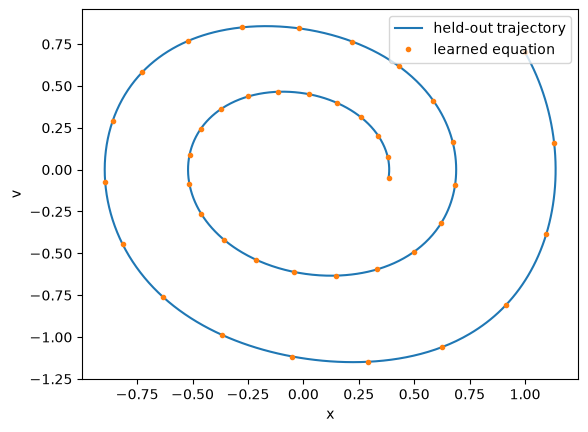

identified coefficients:
 [[ 0.   0. ]
 [ 0.  -1. ]
 [ 1.  -0.2]
 [ 0.   0. ]
 [ 0.   0. ]
 [ 0.   0. ]
 [ 0.  -0.5]
 [ 0.   0. ]
 [ 0.   0. ]
 [ 0.   0. ]]


In [1]:
import numpy as np
import matplotlib.pyplot as plt

def force(z):
    x, v = z
    return np.array([v, -x-0.2*v-0.5*x**3])

def rk4_step(z, dt, rhs):
    k1 = rhs(z)
    k2 = rhs(z+dt*k1/2)
    k3 = rhs(z+dt*k2/2)
    k4 = rhs(z+dt*k3)
    return z+dt*(k1+2*k2+2*k3+k4)/6

def trajectory(z0, steps=1200, dt=0.01, rhs=force):
    out = np.empty((steps+1, 2)); out[0] = z0
    for i in range(steps):
        out[i+1] = rk4_step(out[i], dt, rhs)
    return out

def library(z):
    x, v = np.asarray(z).T
    return np.column_stack([np.ones_like(x), x, v, x*x, x*v, v*v,
                            x**3, x*x*v, x*v*v, v**3])

states = np.vstack([trajectory(z0)[::4] for z0 in
                    ([1.4, 0.0], [-0.8, 0.6], [0.3, -1.2])])
Theta = library(states)
Y = np.array([force(z) for z in states])
Xi = np.linalg.lstsq(Theta, Y, rcond=None)[0]
for _ in range(8):
    active = np.abs(Xi) >= 0.05
    Xi[~active] = 0.0
    for a in range(2):
        Xi[active[:, a], a] = np.linalg.lstsq(
            Theta[:, active[:, a]], Y[:, a], rcond=None)[0]
expected = np.zeros((10, 2))
expected[2, 0] = 1
expected[1, 1], expected[2, 1], expected[6, 1] = -1, -0.2, -0.5
assert np.allclose(Xi, expected, atol=1e-8)

def learned_rhs(z):
    return (library(np.asarray(z)[None, :]) @ Xi)[0]

reference = trajectory([1.0, 0.7])
predicted = trajectory([1.0, 0.7], rhs=learned_rhs)
assert np.max(np.abs(reference-predicted)) < 1e-7
energy = 0.5*predicted[:, 1]**2+0.5*predicted[:, 0]**2+predicted[:, 0]**4/8
assert np.max(np.diff(energy)) < 1e-8
plt.plot(reference[:, 0], reference[:, 1], label="held-out trajectory")
plt.plot(predicted[::30, 0], predicted[::30, 1], ".", label="learned equation")
plt.xlabel("x"); plt.ylabel("v"); plt.legend(); plt.show()
print("identified coefficients:\n", np.round(Xi, 6))

The assertion checks exact recovery in a favorable, noiseless case where the truth is inside the library. To investigate actual scientific reliability, add measurement noise, hide velocity, introduce an unmodeled drive, or train at small amplitude and test at large amplitude. These interventions test distinct assumptions rather than merely making the same benchmark harder.

## Differentiating noisy measurements can dominate the error

If $x_i=x(t_i)+\epsilon_i$ with independent noise variance $\sigma^2$, a centered derivative estimate is $(x_{i+1}-x_{i-1})/(2\Delta t)$. Its noise variance is $2\sigma^2/(4\Delta t^2)=\sigma^2/(2\Delta t^2)$. Smaller time steps improve truncation error but amplify noise in the derivative. Smoothing suppresses noise while introducing bias and correlations; these tradeoffs must enter uncertainty estimates.

An integral formulation avoids explicit differentiation. For a time window $[t_a,t_b]$,

$$
z(t_b)-z(t_a)=\sum_j\Xi_j\int_{t_a}^{t_b}\vartheta_j(z(t))\,dt.
$$

Quadrature approximates the integrals, turning each window into a regression row. Endpoint noise remains, and noisy nonlinear features can still be biased: $\mathbb E[(x+\epsilon)^2]=x^2+\sigma^2$. Integral fitting is not a universal cure. It can, however, remove the explicit $1/\Delta t$ amplification.

A related weak formulation multiplies $\dot z$ by a smooth test function $w$ that vanishes at the window boundaries. Integration by parts gives

$$
\int w\dot z\,dt=-\int\dot w\,z\,dt
=\sum_j\Xi_j\int w\vartheta_j(z)\,dt.
$$

Now no noisy endpoint difference is needed. Choosing many windows and test functions yields a linear system. For partial differential equations the same idea transfers derivatives from measured fields to known test functions in space and time. Boundary terms must be retained unless the chosen support or boundary conditions make them vanish. Sparse PDE discovery is a natural extension of this framework [@d-rudy2017].

## Identifiability: a law is more than a fit on one trajectory

On a unit-amplitude harmonic orbit, $x^2+v^2=1$. Consequently,

$$
\dot v=-x
\quad\text{and}\quad
\dot v=-x+c\,x(x^2+v^2-1)
$$

agree at every point of that orbit for any $c$. The extra term vanishes there. Perfect time resolution and zero measurement noise do not identify $c$. A second orbit of another energy, or a perturbing force that moves the system away from the circle, can distinguish the models. This is **structural nonidentifiability under the available experiments**.

Other equivalences are harmless representation changes. The expressions $2\sin x\cos x$ and $\sin(2x)$ define the same function. Multiplying an implicit equation $F(x)=0$ by a nowhere-zero function leaves its solution set unchanged. Adding a total derivative $dG(q,t)/dt$ to a Lagrangian changes its action only by endpoint terms and leaves the Euler–Lagrange equations unchanged for fixed endpoints. Derive this last statement by varying $\int dG/dt\,dt=G(q_b,t_b)-G(q_a,t_a)$: its variation vanishes when endpoint positions are fixed. A discovery score should account for such equivalences instead of treating different strings as different laws.

Coordinates introduce another ambiguity. A latent variable learned by an autoencoder may mix physical coordinates through an invertible transformation. A simple latent differential equation can be predictive without uniquely identifying a physical observable. Interpreting it requires connecting latent quantities to measurements, transformations, and units. Hybrid methods that fit structured neural models and then extract expressions provide one route to interpretable candidate relations [@d-mcranmer2020].

## Hypotheses, interventions, and causal explanations

A correlation between two measurements need not describe a response to an intervention. For example, suppose an unrecorded environment temperature $u$ changes both resistance $R=R_0+\alpha u$ and oscillator frequency $\omega=\omega_0+\beta u$. Eliminating $u$ gives a perfect relation between $R$ and $\omega$, but changing resistance by replacing a resistor need not change the oscillator frequency as that relation predicts. The omitted common cause explains the observed association.

A causal claim specifies what is held fixed and what is actively changed. Equation discovery from passive trajectories needs assumptions about state completeness, external inputs, noise, and stationarity. To test a proposed force law, vary initial conditions, drive the system with known inputs, and check whether the same coefficients predict all interventions. In quantum experiments, preparation and measurement errors can mimic changes in the state or dynamics; independent calibrations and alternative measurement settings help separate them.

A useful hypothesis produces a risky prediction: a result that could plausibly have failed and was not used to select the hypothesis. Repeatedly adjusting a model against the same “test” experiment turns that experiment into training data. Keep a final prospective test, prerecord the predicted observable and uncertainty, and retain unsuccessful hypotheses in the research record. The purpose is to make evidence interpretable, not to forbid exploratory work.

## Language models and scientific agents

A language model can propose candidate equations, write simulator code, search a literature corpus, and organize an experimental workflow. A **scientific agent** combines such proposals with tools and a policy for choosing actions. The decisive component is the external verification loop: dimensional checks, numerical solvers, proof checks, statistical tests, and physical measurements.

Code-generating models have been investigated for families of quantum experiment designs, including general design rules checked in the task's formal representation [@d-arlt2026]. A correct design in an ideal optical model still needs loss, distinguishability, fabrication, and calibration analysis before it becomes a working experiment. Likewise, a formal proof verifies a proposition under stated axioms; it does not certify that the axioms describe a laboratory.

Treat generated citations as search suggestions until authors, title, date, and identifier are verified. Treat generated derivations as drafts until every nontrivial step and assumption is checked. A simulator that evaluates proposals should be independently tested; otherwise an agent may exploit its bugs. A search that evaluates a million proposals also needs to account for selection: an apparently impressive noisy score can be the most fortunate fluctuation.

One productive division of labor is to let flexible models generate possibilities while restrictive tools eliminate invalid ones. Dimensional grammars can forbid invalid expressions. Symmetry constraints can eliminate impossible terms. Sparse fitting can estimate remaining coefficients. Experiments can distinguish survivors. The resulting scientific claim should state the generated object, the verification performed, the tested domain, and what remains conjectural.

## Exercises and worked answers

1. From the variables $E,m,c$, derive the only product with energy dimensions, assuming no other dimensional constants. Does dimensional analysis establish relativity?
2. Explain why training the oscillator model only on $x=0,v=0$ cannot determine any force coefficients even with exact derivatives.
3. Add the force term $-0.1x^5$ to the simulator but keep the cubic library. Predict how training-amplitude and testing-amplitude changes expose the omission.
4. Derive the weak identity when the test function does not vanish at the endpoints.

**Answers.** In exercise 1, $m^ac^b$ has dimensions $\mathsf M^a\mathsf L^b\mathsf T^{-b}$, requiring $a=1,b=2$. Thus $E=Cmc^2$ is dimensionally possible, but neither its coefficient nor its physical interpretation follows. In exercise 2 every nonconstant library column vanishes and all derivative targets vanish; infinitely many coefficient vectors agree at that one state. In exercise 3, at small $x$ the omitted fifth power is tiny and may be absorbed into slightly biased linear and cubic coefficients. At larger amplitude it grows faster and produces systematic acceleration and period errors. In exercise 4, integration by parts gives $[wz]_{t_a}^{t_b}-\int\dot w z\,dt=\sum_j\Xi_j\int w\vartheta_j\,dt$. Dropping the boundary term without justification fits the wrong equation.